### This notebook contains code to recreate simple (non model-based) analyses of behaviour 

Code for Figure 1b, Supplementary figures 1b,c,d

To run this code, you need to use the processed behavioural data, found in the folder fmri_study/data/behav_data/processed/

To process the raw behavioural data from scratch, open the script 'preprocess_data' in the folder 'behav_preprocessing'

Eleanor Holton, Last edited 19/01/2024

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
import statsmodels.api as sm
import scipy.stats as stats


In [2]:
# Parameters

nParticipants = 30
participants = range(nParticipants)

# plotting parameters
val_type_colours = ["#1E88E5", "#E66100"]
quartiles_colours = sns.color_palette("Purples")[:][2:6] 
model_colours = ["#D3D3D3","#D3D3D3", "#D3D3D3", quartiles_colours[3]]
bias_color='g'

small_label_fontsize = 15
medium_label_fontsize=18

In [ ]:
# Import data 
base_folder = ''
data_folder = base_folder + '/data/mri_study/behaviour/'
figure_folder = ''

# Specify data folders for scan and post-scan testing sessions 
scanner_data_folder = data_folder + 'processed/scan_session/'
post_scanner_data_folder =data_folder + 'processed/post_scan_session/'

# Concatenate scanner and post-scanner data for full data set 
df_full = pd.DataFrame()
df_scanner = pd.DataFrame()
df_postscanner = pd.DataFrame()

for p in range(nParticipants):
    
    p_scanner = pd.read_csv(scanner_data_folder + 'scan_sub_' + str(p) + '.csv')
    p_postScanner = pd.read_csv(post_scanner_data_folder + 'post_scan_sub_' + str(p) + '.csv')
    
    #Merge total trials and total blocks across sessions in combined dataframe 
    scan_maxTrial = p_scanner['total_trial_number'].max()
    scan_maxBlock = p_scanner['block'].max()
    
    p_postScanner['total_trial_number']+=scan_maxTrial
    p_postScanner['block']+=scan_maxBlock
      
    df_full = pd.concat((df_full, p_scanner, p_postScanner))
    df_scanner = pd.concat((df_scanner, p_scanner))
    df_postscanner = pd.concat((df_postscanner, p_postScanner))

df_full = df_full.reset_index()
df_scanner = df_scanner.reset_index()
df_postscanner = df_postscanner.reset_index()


#### Figure 1b - example participant block

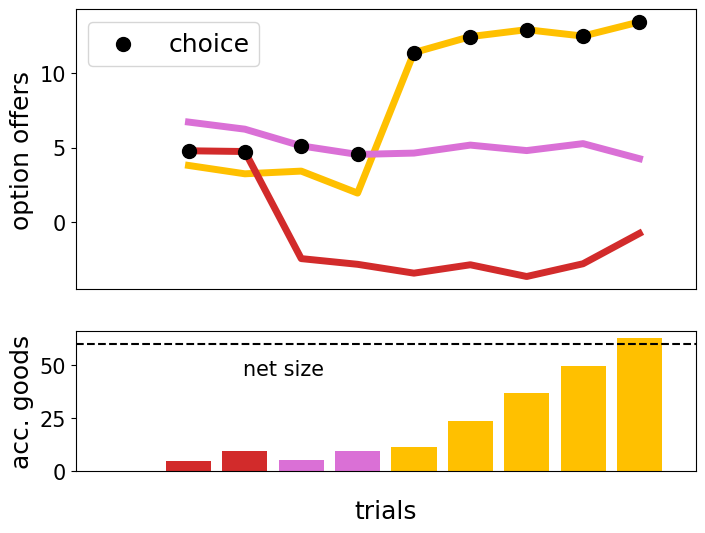

In [5]:
# Define accumulated value as aggregate value AFTER CHOICE (in contrast to net contents)
mags_tab = df_scanner[["magnitudes_1","magnitudes_2","magnitudes_3"]]
goods_added = []
accum_val = []
for t in range(mags_tab.shape[0]):
    goods_added.append(mags_tab.iloc[t,df_scanner['choice'].iloc[t]-1])
    if df_scanner['switch_trial'].iloc[t]==0:
        accum_val.append(df_scanner["net_contents"].iloc[t]+goods_added[t])
    elif df_scanner['switch_trial'].iloc[t]==1:
        accum_val.append(goods_added[t])
        

df_scanner["goods_added"] = goods_added
df_scanner["accum_val"] = accum_val

creature_cols = ['#FFC000', '#DA70D6', '#D22B2B']

# Example trial
thisP=0
thisB=6

trial_df = df_scanner.loc[(df_scanner.participant==thisP)&(df_scanner.block==thisB)]

gs_kw = dict( height_ratios=[2, 1])
fig,axes = plt.subplots(2,1,figsize=[8,6],gridspec_kw=gs_kw,sharex=True)

axes[0].plot(trial_df["trial_number"],trial_df["magnitudes_1"],color=creature_cols[0],linewidth=5,zorder=1)
axes[0].plot(trial_df["trial_number"],trial_df["magnitudes_2"],color=creature_cols[1],linewidth=5,zorder=2)
axes[0].plot(trial_df["trial_number"],trial_df["magnitudes_3"],color=creature_cols[2],linewidth=5,zorder=3)
axes[0].scatter(trial_df["trial_number"],trial_df["goods_added"],color='k',s=100,zorder=4,label='choice')
axes[0].set_ylabel('option offers',fontsize=medium_label_fontsize)
axes[0].legend(fontsize=medium_label_fontsize)
axes[0].tick_params(axis='y', labelsize=small_label_fontsize)
axes[0].set_xticks([])
axes[0].set_xlim([-1,10])

bar_cols = []
bar_cols.append([creature_cols[p-1] for p in trial_df["choice"]])
axes[1].bar(trial_df["trial_number"], trial_df["accum_val"],color=bar_cols[0])
axes[1].axhline(np.unique(trial_df["goal_size"].values),color='k',linestyle='--',label='net size')
axes[1].set_xlabel('trials',fontsize=medium_label_fontsize,labelpad=20)
axes[1].set_ylabel('acc. goods',fontsize=medium_label_fontsize)
#axes[1].legend(fontsize=medium_label_fontsize,frameon=False)
axes[1].annotate('net size', xy=(0.4,0.8), xycoords='axes fraction',
            size=small_label_fontsize, ha='right', va='top')
axes[1].tick_params(axis='y', labelsize=small_label_fontsize)
axes[1].tick_params(axis='x', labelsize=small_label_fontsize)

fig_name = 'fig1_task_singleTrial.png'
#fig.savefig(figure_folder + '/' +fig_name,bbox_inches='tight',dpi=300)

#### Supplementary figure 2b - Results of a logistic regression analysis predicting goal switching as a function of simple task parameters 

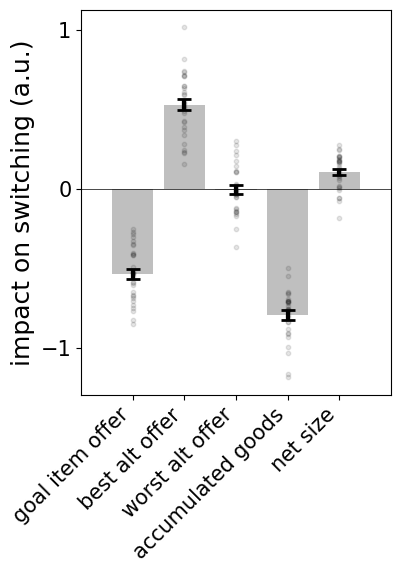

In [6]:
# Define simple regressors
simple_regs = ['mag_goal_item', 'mag_best_alt','mag_worst_alt','net_contents','goal_size']
nRegs = len(simple_regs)
coeff_matrix = np.empty(shape=(nParticipants, nRegs), dtype='object')

# Fit coefficients at participant level
for p_ID,p_count in zip(participants, range(nParticipants)):
    p_df = df_scanner.loc[df_scanner["participant"]==p_ID]
    df_regs = p_df[simple_regs]
    normalized_df=(df_regs-df_regs.mean())/df_regs.std()
    glm_binom = sm.GLM(p_df[['switch_trial']], normalized_df, family=sm.families.Binomial(),missing='drop')
    result = glm_binom.fit()
    for reg_name,reg_count in zip(simple_regs, range(nRegs)):
        coeff_matrix[p_count,reg_count] = result.params[reg_name]
    
    
# Plot 
coef_df = pd.DataFrame(coeff_matrix, columns = simple_regs)
fig, ax = plt.subplots(figsize=[4,5])
ax.axhline(0,color='k',linewidth=.5)
ax.bar(np.arange(0,nRegs), coef_df.mean(),color='grey',alpha=0.5)

# Scatter individual participant coefficients
for reg_name,reg_count in zip(simple_regs, range(nRegs)):
    ax.scatter(np.tile(reg_count, (nParticipants)), coef_df[reg_name],color='k',alpha=0.1,s=10)
    
(_, caps, _) = ax.errorbar(np.arange(0,nRegs), coef_df.mean(),coef_df.sem(),color='k',linewidth=3,linestyle='',capsize=5)
for cap in caps:
    cap.set_markeredgewidth(2)
 
ax.set_ylabel('impact on switching (a.u.)',fontsize=medium_label_fontsize)
ax.set_xlabel('')
ax.set_xticks(np.arange(0,nRegs),['goal item offer','best alt offer','worst alt offer','accumulated goods','net size'],rotation=45,ha = 'right')
ax.set_xlim([-1,nRegs])
ax.set_yticks([-1,0,1])
ax.tick_params(axis='both', which='major', labelsize=small_label_fontsize)

#fig.savefig(figure_folder+'simple_regressors.png',bbox_inches='tight',dpi=300)

In [7]:
# Statistics 

for idx,sr in enumerate(simple_regs):
    print(sr)
    print(stats.ttest_1samp(list(coeff_matrix[:,idx]),popmean=0))

mag_goal_item
TtestResult(statistic=-16.842444436449675, pvalue=1.6322079123587626e-16, df=29)
mag_best_alt
TtestResult(statistic=14.737902953727241, pvalue=5.2881714772004595e-15, df=29)
mag_worst_alt
TtestResult(statistic=-0.11172690529444439, pvalue=0.9118096879149551, df=29)
net_contents
TtestResult(statistic=-27.673330954397557, pvalue=2.1157631508544424e-22, df=29)
goal_size
TtestResult(statistic=5.353150476672984, pvalue=9.507824658517967e-06, df=29)


#### Supplementary figure 2c - Reaction time plot (for reviewers)

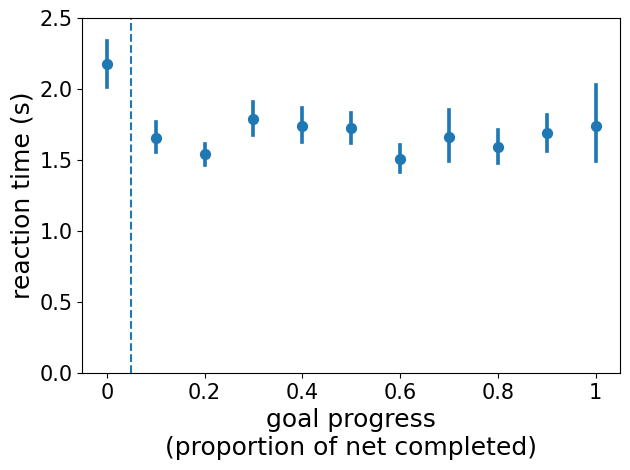

In [8]:
fig,ax=plt.subplots()
sns.regplot(ax=ax,
            x = "prop_filled",
            y = "decisionRT",
            data = df_postscanner,
            x_bins=np.arange(0, 1.1, 0.1),
            line_kws={'linewidth':0.0001})

plt.setp(ax.collections[1], alpha=0.00001)
ax.set_ylabel('reaction time (s)',fontsize=medium_label_fontsize)
ax.set_yticks(np.arange(0,3,0.5),np.arange(0,3,0.5),fontsize=small_label_fontsize)
ax.set_xlabel('goal progress\n(proportion of net completed)',fontsize=medium_label_fontsize)
ax.set_xticks(np.arange(0,1.1,0.2),['0','0.2','0.4','0.6','0.8','1'],fontsize=small_label_fontsize)
ax.axvline(0.05,linestyle='--')
fig.tight_layout()

#fig.savefig(figure_folder+'RTs_reviewers.png',bbox_inches='tight')

#### Supplementary figure 2d - RT by trial-type (for reviewers)

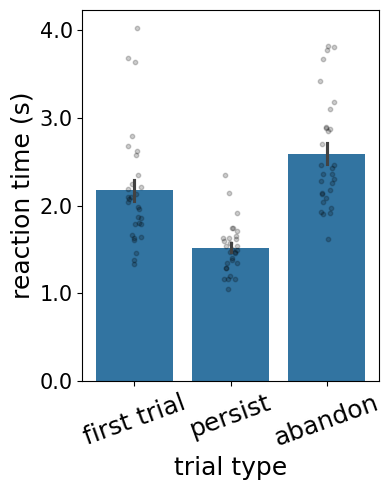

In [9]:
# Reaction time plot by trial type 
df_postscanner['trial_category']=df_postscanner['switch_trial']+1
df_postscanner.loc[df_postscanner['trial_number']==1,'trial_category']=0

participant_mean_df = df_postscanner.groupby(['participant','trial_category']).mean().reset_index()

fig,ax=plt.subplots(figsize=[4,5])
sns.barplot(ax=ax,
            x = "trial_category",
            y = "decisionRT",
            data = participant_mean_df,
            errorbar='se')

for tc in range(3):
    ax.scatter(np.tile(tc, nParticipants)+0.15*(np.random.rand(nParticipants)-0.5),participant_mean_df.loc[participant_mean_df['trial_category']==tc,'decisionRT'],color='k',alpha=0.2,s=10)

ax.set_ylabel('reaction time (s)',fontsize=medium_label_fontsize)
ax.set_yticks(np.arange(0,4.5,1),np.arange(0,4.5,1),fontsize=small_label_fontsize)
ax.set_xlabel('trial type',fontsize=medium_label_fontsize)
ax.set_xticks([0,1,2],['first trial','persist','abandon'],fontsize=medium_label_fontsize,rotation=20)
fig.tight_layout()

#fig.savefig(figure_folder+'RTs_abandonment.png',bbox_inches='tight')

In [10]:
# statistics
rt_table = df_postscanner.groupby(['participant','trial_category'])['decisionRT'].mean().reset_index()
print('\nfirst trial vs persist:')
print(stats.ttest_rel(rt_table.loc[rt_table['trial_category']==0,'decisionRT'], rt_table.loc[rt_table['trial_category']==1,'decisionRT']))
print('\nfirst trial vs abandon:')
print(stats.ttest_rel(rt_table.loc[rt_table['trial_category']==0,'decisionRT'], rt_table.loc[rt_table['trial_category']==2,'decisionRT']))
print('\npersist vs abandon:')
print(stats.ttest_rel(rt_table.loc[rt_table['trial_category']==1,'decisionRT'], rt_table.loc[rt_table['trial_category']==2,'decisionRT']))



first trial vs persist:
TtestResult(statistic=6.055491608641209, pvalue=1.3680080390841541e-06, df=29)

first trial vs abandon:
TtestResult(statistic=-2.9916820297819413, pvalue=0.005614461284668984, df=29)

persist vs abandon:
TtestResult(statistic=-11.058752173039014, pvalue=6.415248448526402e-12, df=29)
